# Modification

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

In [1]:
# Downloading data

import os

# has to be set before keras is imported
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['KERAS_HOME'] = os.path.abspath('resources/data')
import keras
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images_per_class = 3
rng_seed = 42
folder_name = "resources/data"

# Solution
folder_path = Path(folder_name)
folder_path.mkdir(parents=True, exist_ok=True)

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(rng_seed)
np.random.seed(rng_seed)

# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# The labels come as (N, 1) arrays, flatten them to (N,)
y_train, y_test = y_train.flatten(), y_test.flatten()

# analysis image
example_img = x_train[0]

# Mapping from class ID to class name
classes = {0: 'plane', 1: 'car', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}

preview_samples = []
# preparing set of images for showing
for class_id in range(len(classes)):
    # filter indexes of the necessary class
    class_indices = np.where(y_train == class_id)[0]
    # get 3 random images
    random_indices = np.random.choice(class_indices, size=n_images_per_class, replace=False)
    # add images to list
    for idx in random_indices:
        preview_samples.append((classes[class_id], x_train[idx]))

rp = rpt.Reporter()
rp.add_item("Dataset directory", folder_name)
rp.add_item("Image: (rows, cols, channels)", str(example_img.shape))
rp.add_item("Pixel value range", f"[{x_train.min()}, {x_train.max()}] ({x_train.dtype})")
rp.add_item("Number of items in the train dataset", f"{len(y_train)} samples")
rp.add_item("Number of items in the test dataset", f"{len(y_test)} samples")
rp.add_item("Count of classes", str(len(classes)))
for key, value in classes.items():
    rp.add_item(f"Class: {value}", f"id: {key}")

# Print results
rp.print_pd_report("Report of CIFAR-10 Dataset Inspection")


Attribute,Result
Dataset directory,resources/data
"Image: (rows, cols, channels)","(32, 32, 3)"
Pixel value range,"[0, 255] (uint8)"
Number of items in the train dataset,50000 samples
Number of items in the test dataset,10000 samples
Count of classes,10
Class: plane,id: 0
Class: car,id: 1
Class: bird,id: 2
Class: cat,id: 3


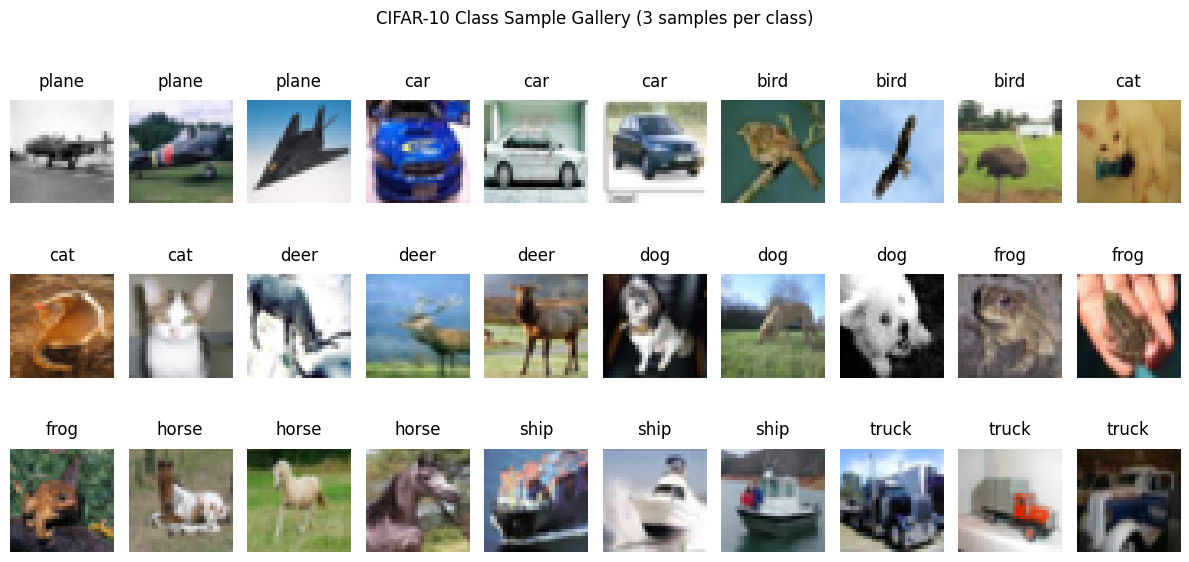

In [2]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 10
images_list = preview_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("CIFAR-10 Class Sample Gallery (3 samples per class)", y=1.0)
plt.tight_layout()
plt.show()


Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

In [3]:
# Compute the class histogram

import numpy as np
import apps.reporter as rpt

# Input data

# Solution
class_names = list(classes.values())

# calculate count of each classes
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

# check balancing
is_train_balanced = len(set(train_counts)) == 1
is_test_balanced = len(set(test_counts)) == 1

rp = rpt.Reporter()
rp.add_item("Is Train dataset balanced?", 'Yes' if is_train_balanced else 'No')
rp.add_item("Is Test dataset balanced?", 'Yes' if is_test_balanced else 'No')

# Print results
rp.print_pd_report("Report of CIFAR-10 Class Balance")

Attribute,Result
Is Train dataset balanced?,Yes
Is Test dataset balanced?,Yes


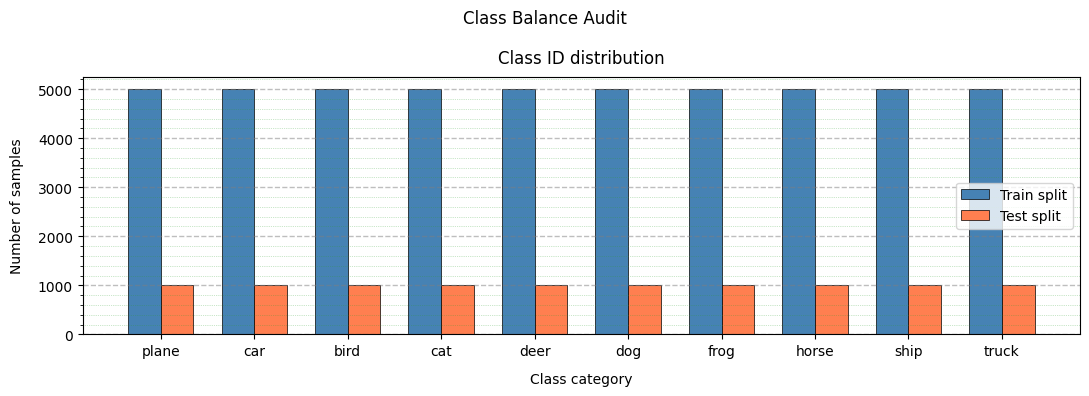

In [4]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
x_indices = np.arange(len(class_names))
bar_width = 0.35

# Solution
_, ax = plt.subplots(figsize=(11, 4))

ax.bar(x_indices - bar_width / 2, train_counts, bar_width,
       label='Train split', color='steelblue', edgecolor='black', linewidth=0.5)
ax.bar(x_indices + bar_width / 2, test_counts, bar_width,
       label='Test split', color='coral', edgecolor='black', linewidth=0.5)

ax.set_xticks(x_indices)
ax.set_xticklabels(class_names, rotation=0, ha='center')
ax.tick_params(axis='x', which='minor', bottom=False, top=False)

ax.grid(axis='y', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
ax.minorticks_on()
ax.grid(axis='y', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Class ID distribution", pad=10, loc='center', color='black')
ax.set_xlabel("Class category", labelpad=10, loc='center', color='black')
ax.set_ylabel("Number of samples", labelpad=10, loc='center', color='black')

ax.legend(frameon=True, loc='center right')
plt.suptitle("Class Balance Audit")

plt.tight_layout()
plt.show()


### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [5]:
# Normalization/Scaling & One-hot encoding

import apps.reporter as rpt
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Input data
is_standard_scaler = True
num_samples_train, height, width, channels = x_train.shape
num_samples_test = x_test.shape[0]

# Solution
scaler = StandardScaler() if is_standard_scaler else MinMaxScaler(feature_range=(0, 1))

# Flatten
x_train_flat = x_train.reshape(num_samples_train, -1)
x_test_flat = x_test.reshape(num_samples_test, -1)

# Scaling / Normalization
x_train_flat = scaler.fit_transform(x_train_flat)
x_test_flat = scaler.transform(x_test_flat)

# Reshape
x_train_n_sc = x_train_flat.reshape(num_samples_train, height, width, channels)
x_test_n_sc = x_test_flat.reshape(num_samples_test, height, width, channels)

# One-hot encoding
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=len(class_names))
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=len(class_names))

rp = rpt.Reporter()
rp.add_item("Preprocessing method", 'Standardization' if is_standard_scaler else 'Min-Max Normalization')
rp.add_item("Train set", f"{len(y_train)} samples")
rp.add_item("Train sample dims", str(x_train_n_sc.shape))
rp.add_item("Train label dims", str(y_train_ohe.shape))
rp.add_item("Train pixel range", f"[{x_train_n_sc.min():.1f}, {x_train_n_sc.max():.1f}], dtype: {x_train_n_sc.dtype}")
rp.add_item("Test set", f"{len(y_test)} samples")
rp.add_item("Test sample dims", str(x_test_n_sc.shape))
rp.add_item("Test label dims", str(y_test_ohe.shape))
rp.add_item("Test pixel range", f"[{x_test_n_sc.min():.1f}, {x_test_n_sc.max():.1f}], dtype: {x_test_n_sc.dtype}")

# Print results
rp.print_pd_report("Report of CIFAR-10 Data Preparation")

Attribute,Result
Preprocessing method,Standardization
Train set,50000 samples
Train sample dims,"(50000, 32, 32, 3)"
Train label dims,"(50000, 10)"
Train pixel range,"[-2.2, 2.6], dtype: float64"
Test set,10000 samples
Test sample dims,"(10000, 32, 32, 3)"
Test label dims,"(10000, 10)"
Test pixel range,"[-2.2, 2.6], dtype: float64"


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

Note that, unlike MNIST, the CIFAR-10 images are color (RGB) images.

Model: "cifar10_modified_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_1_conv (Conv2D)      │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_1_pool               │ (None, 16, 16, 16)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2_conv (Conv2D)      │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2_pool               │ (None, 8, 8, 32)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_features (Flatten)      │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 16)             │        32,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_output (Dense)       │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,042 (148.60 KB)

 Trainable params: 38,042 (148.60 KB)

 Non-trainable params: 0 (0.00 B)

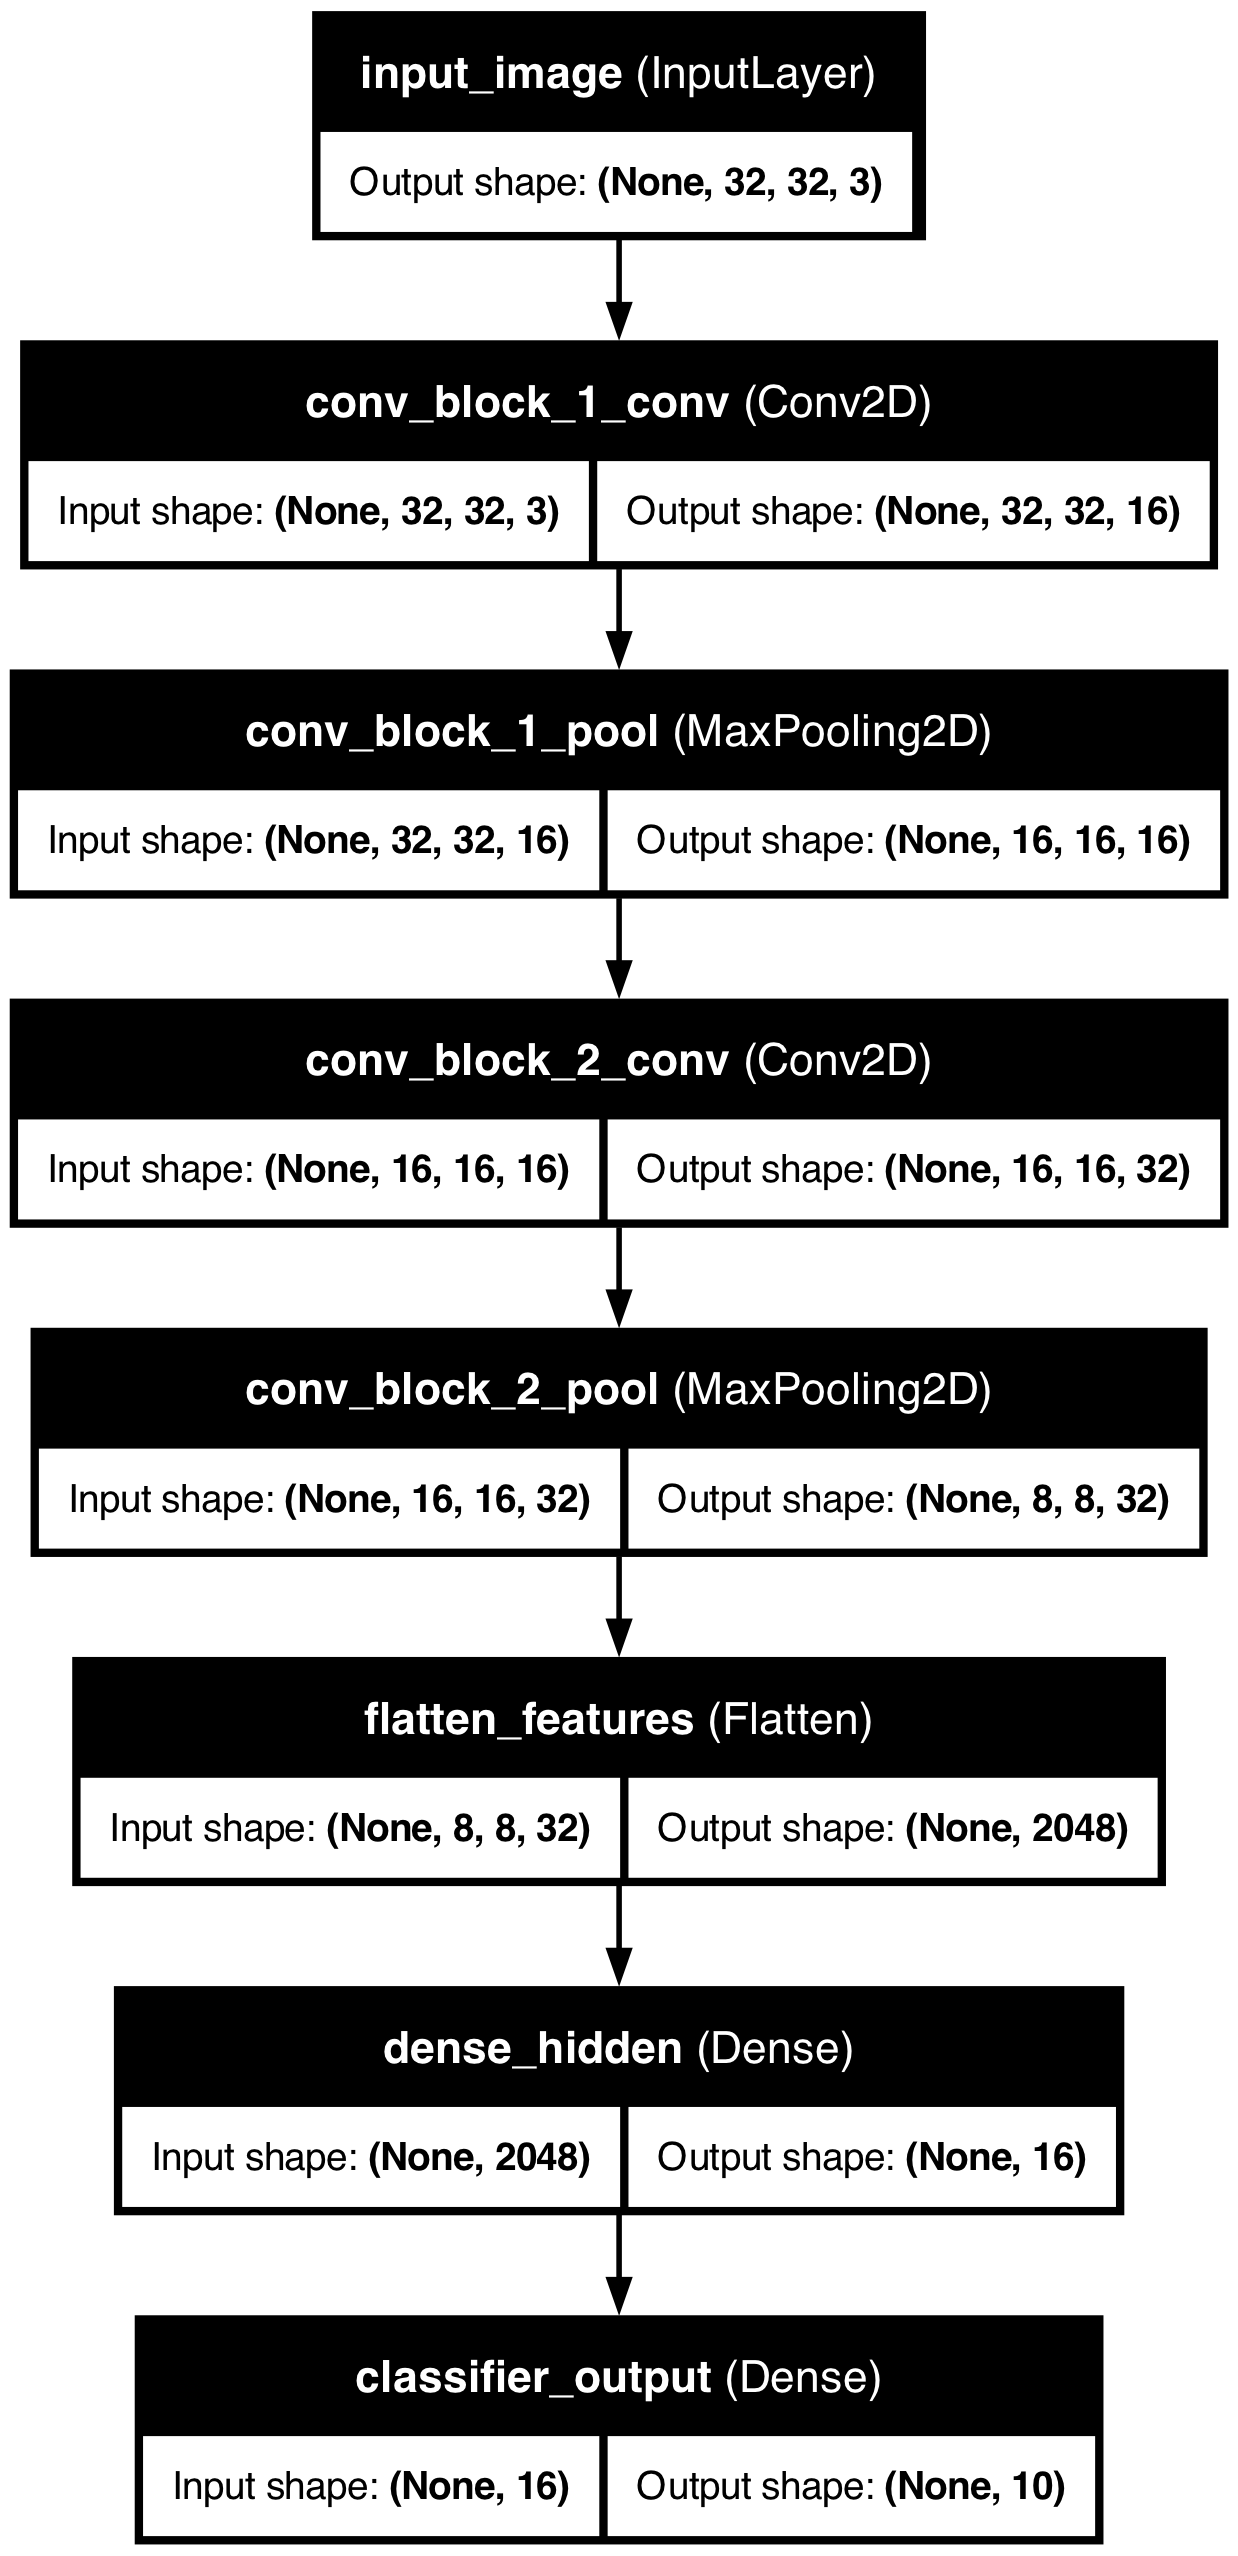

In [6]:
# Build the classifier

from keras import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from IPython.display import display

# Input data
rng_seed = 42

# Solution
keras.utils.set_random_seed(rng_seed)


# Preparing model
def build_model():
    inputs = Input(shape=example_img.shape, name="input_image")
    net = Conv2D(16, kernel_size=(3, 3), activation="elu", kernel_initializer="he_normal",
                 padding="same", name="conv_block_1_conv")(inputs)
    net = MaxPooling2D(pool_size=(2, 2), name="conv_block_1_pool")(net)
    net = Conv2D(32, kernel_size=(3, 3), activation="elu", kernel_initializer="he_normal",
                 padding="same", name="conv_block_2_conv")(net)
    net = MaxPooling2D(pool_size=(2, 2), name="conv_block_2_pool")(net)
    net = Flatten(name="flatten_features")(net)
    net = Dense(16, activation="leaky_relu", kernel_initializer="he_normal", name="dense_hidden")(net)
    outputs = Dense(len(class_names), activation="softmax", name="classifier_output")(net)
    return Model(inputs=inputs, outputs=outputs, name="cifar10_modified_cnn")


model = build_model()

# Print results
model.summary()
# Show the model architecture summary
try:
    display(keras.utils.plot_model(model, to_file=f"{folder_name}/model_m.png", show_shapes=True, show_layer_names=True))
except Exception:
    pass

### Step 3: Training

Compile the model and train it.

In [7]:
# Training

import importlib
import keras
import apps.main as mn
import apps.reporter as rpt

importlib.reload(mn)
importlib.reload(rpt)

# Input data
learning_rate = 0.001
epochs = 10
batch_size = 128
validation_split = 0.1

# Solution
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
loss = keras.losses.CategoricalCrossentropy()

# Compile the model
model.compile(optimizer=optimizer, loss=loss, metrics=["accuracy"])

# Train the model
history = model.fit(x_train_n_sc, y_train_ohe, epochs=epochs, batch_size=batch_size,
                    validation_split=validation_split, verbose=0, callbacks=[mn.TqdmProgressCallback(epochs)])

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Model Architecture", "Modified CNN (Conv2D 32 -> MaxPool -> Conv2D 64 -> MaxPool -> Dense 128 -> Dense 10)")
rp.add_item("Trainable Parameters", f"{model.count_params():,}")
rp.add_item("Loss Function", "Categorical Cross-Entropy (CCE)")
rp.add_item("Optimizer", "Adam")
rp.add_item("Learning Rate", rp.format_value(learning_rate))
rp.add_item("Batch Size", str(batch_size))
rp.add_item("Epochs", str(epochs))
rp.add_item("Initial Train Loss", rp.format_value(history.history['loss'][0]))
rp.add_item("Final Train Loss", rp.format_value(history.history['loss'][-1]))
rp.add_item("Final Validation Loss", rp.format_value(history.history['val_loss'][-1]))
rp.add_item("Initial Train Accuracy", rp.format_value(history.history['accuracy'][0]))
rp.add_item("Final Train Accuracy", rp.format_value(history.history['accuracy'][-1]))
rp.add_item("Final Validation Accuracy", rp.format_value(history.history['val_accuracy'][-1]))

# Print results
rp.print_pd_report("Report of CIFAR-10 Modified CNN Training")


Total training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Loss: 1.5720, Accuracy: 0.4429, Status: 10.00%
Epoch: 2, Loss: 1.1701, Accuracy: 0.5888, Status: 20.00%
Epoch: 3, Loss: 1.0296, Accuracy: 0.6383, Status: 30.00%
Epoch: 4, Loss: 0.9556, Accuracy: 0.6642, Status: 40.00%
Epoch: 5, Loss: 0.8943, Accuracy: 0.6856, Status: 50.00%
Epoch: 6, Loss: 0.8490, Accuracy: 0.7026, Status: 60.00%
Epoch: 7, Loss: 0.8136, Accuracy: 0.7161, Status: 70.00%
Epoch: 8, Loss: 0.7819, Accuracy: 0.7260, Status: 80.00%
Epoch: 9, Loss: 0.7536, Accuracy: 0.7375, Status: 90.00%
Epoch: 10, Loss: 0.7259, Accuracy: 0.7462, Status: 100.00%


Attribute,Result
Model Architecture,Modified CNN (Conv2D 32 -> MaxPool -> Conv2D 64 -> MaxPool -> Dense 128 -> Dense 10)
Trainable Parameters,"38,042"
Loss Function,Categorical Cross-Entropy (CCE)
Optimizer,Adam
Learning Rate,0.0010
Batch Size,128
Epochs,10
Initial Train Loss,1.5720
Final Train Loss,0.7259
Final Validation Loss,0.9405


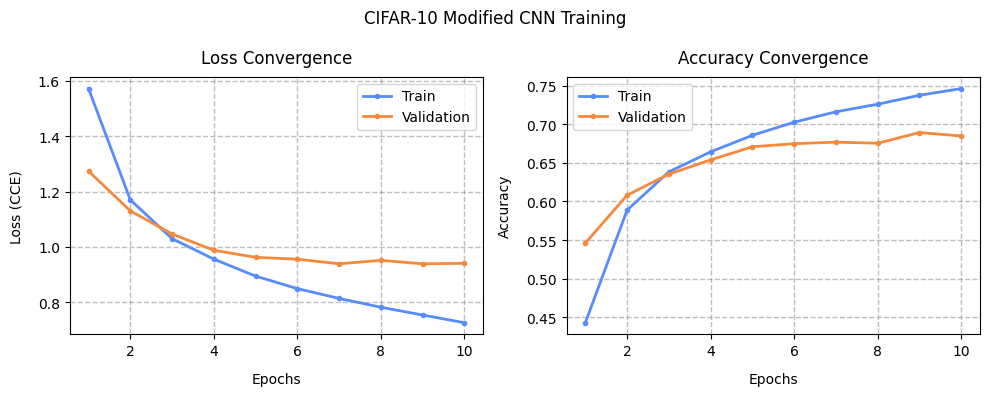

In [8]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, epochs + 1)
array_y00 = history.history['loss']
array_y01 = history.history['val_loss']
array_y10 = history.history['accuracy']
array_y11 = history.history['val_accuracy']

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y00, ls='-', marker='.', linewidth=2.0, label='Train')
ax.plot(array_x, array_y01, ls='-', marker='.', linewidth=2.0, label='Validation')
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epochs", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (CCE)", labelpad=10, loc='center', color='black')
ax.legend()

ax = axes[1]
ax.plot(array_x, array_y10, ls='-', marker='.', linewidth=2.0, label='Train')
ax.plot(array_x, array_y11, ls='-', marker='.', linewidth=2.0, label='Validation')
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epochs", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')
ax.legend()

plt.suptitle(f"CIFAR-10 Modified CNN Training")

plt.tight_layout()
plt.show()

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [9]:
# Evaluation

import importlib
import numpy as np
import apps.main as mn
import apps.reporter as rpt
from apps.reporter import Reporter

importlib.reload(mn)

# Input data

# Solution
# Check the overall stats
ev_loss, ev_accuracy = model.evaluate(x_test_n_sc, y_test_ohe, verbose=0)

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Test loss", rp.format_value(ev_loss))
rp.add_item("Test metric", rp.format_value(ev_accuracy))

# Compute the labels and the predictions as sparse values
y_pred_probs = model.predict(x_test_n_sc, verbose=0, callbacks=[mn.TqdmProgressCallback()])
y_probs = np.max(y_pred_probs, axis=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_ohe, axis=1)

# Compute and print the accuracy for each class
classes_comparison = []
for class_id, class_name in classes.items():
    y_true_binary = (y_true == class_id).astype(int)
    y_pred_binary = (y_pred == class_id).astype(int)
    y_prob_binary = y_pred_probs[:, class_id]
    # form unique report
    classes_comparison.append((f"Metrics: {class_name}",
                               mn.calc_class_metrics(y_true_binary, y_pred_binary, y_prob_binary,
                                                     is_print=False, is_charts=False)))

# Print results
rp.print_pd_report("The overall stats")
_ = mn.calc_class_metrics(y_true, y_pred, caption="Global Classification Metrics")

Reporter.print_concat_pd_reports(classes_comparison, "Comparative Per-Class Classification Performance")

Predicting:   0%|          | 0/313 [00:00<?, ?it/s]

Attribute,Result
Test loss,0.9834
Test metric,0.6741


Attribute,Result
Accuracy (Точність),0.6741
Precision (Влучність),0.6705
Recall (Повнота),0.6741
F1-score,0.6712


              precision    recall  f1-score   support

           0       0.71      0.70      0.70      1000
           1       0.78      0.78      0.78      1000
           2       0.56      0.53      0.55      1000
           3       0.51      0.44      0.47      1000
           4       0.67      0.58      0.62      1000
           5       0.55      0.58      0.57      1000
           6       0.72      0.81      0.76      1000
           7       0.72      0.76      0.74      1000
           8       0.78      0.79      0.78      1000
           9       0.70      0.78      0.74      1000

    accuracy                           0.67     10000
   macro avg       0.67      0.67      0.67     10000
weighted avg       0.67      0.67      0.67     10000



,Confusion Matrix,Accuracy (Точність),Precision (Влучність),Recall (Повнота),F1-score,Receiver Operating Characteristic (ROC-AUC),Average Precision (AP)
Metrics: plane,[[8713 287] [ 303 697]],0.9410,0.7083,0.6970,0.7026,0.9552,0.7715
Metrics: car,[[8785 215] [ 220 780]],0.9565,0.7839,0.7800,0.7820,0.9774,0.8629
Metrics: bird,[[8589 411] [ 469 531]],0.9120,0.5637,0.5310,0.5469,0.8931,0.5688
Metrics: cat,[[8571 429] [ 561 439]],0.9010,0.5058,0.4390,0.4700,0.8840,0.4893
Metrics: deer,[[8711 289] [ 419 581]],0.9292,0.6678,0.5810,0.6214,0.9370,0.6799
Metrics: dog,[[8535 465] [ 423 577]],0.9112,0.5537,0.5770,0.5651,0.9236,0.6312
Metrics: frog,[[8681 319] [ 192 808]],0.9489,0.7169,0.8080,0.7598,0.9697,0.8387
Metrics: horse,[[8711 289] [ 240 760]],0.9471,0.7245,0.7600,0.7418,0.9624,0.8233
Metrics: ship,[[8775 225] [ 215 785]],0.9560,0.7772,0.7850,0.7811,0.9732,0.8639
Metrics: truck,[[8670 330] [ 217 783]],0.9453,0.7035,0.7830,0.7411,0.9686,0.8232


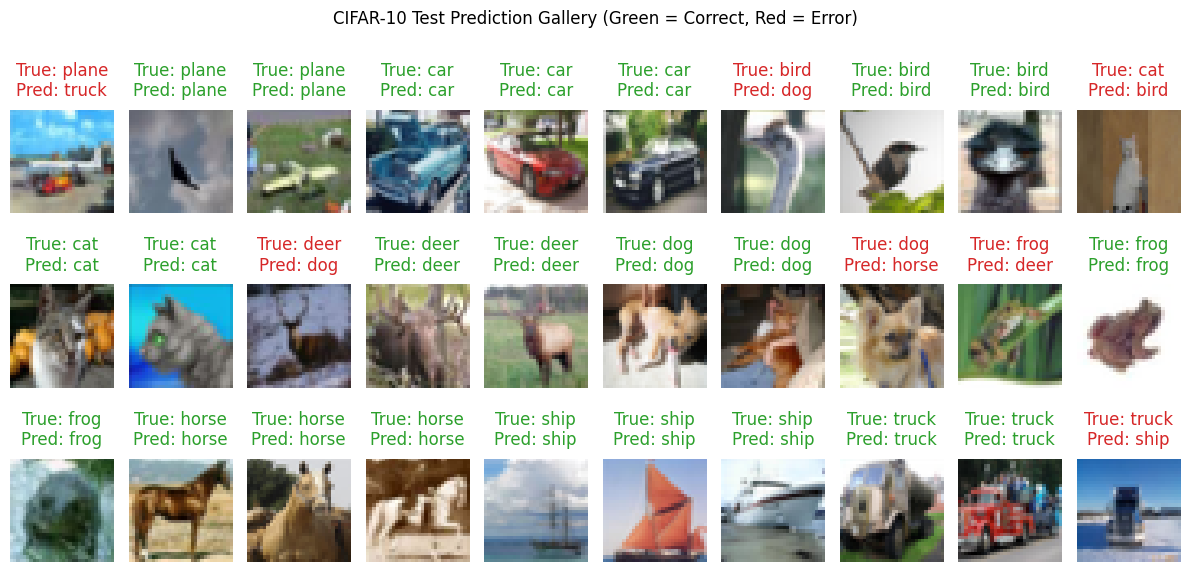

In [10]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_images_per_class = 3
n_img_cols = 10

# Solution
analysis_samples = []
analysis_colors = []
# preparing set of images for analysis
for class_id in range(len(classes)):
    # filter indexes of the necessary class
    class_indices = np.where(y_test == class_id)[0]
    # get 3 random images
    random_indices = np.random.choice(class_indices, size=n_images_per_class, replace=False)
    # add images to list
    for idx in random_indices:
        # add image
        key = f"True: {classes[y_true[idx]]}\nPred: {classes[y_pred[idx]]}"
        value = x_test[idx]
        analysis_samples.append((key, value))

        # add color
        is_correct = (y_true[idx] == y_pred[idx])
        title_color = 'tab:green' if is_correct else 'tab:red'
        analysis_colors.append(title_color)

images_list = analysis_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color=analysis_colors[idx])
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("CIFAR-10 Test Prediction Gallery (Green = Correct, Red = Error)", y=1.0)
plt.tight_layout()
plt.show()
